# 沪深300动量因子研究

保留原研究计算口径和顺序：20日动量 → RankIC/ICIR → 五分组 → 每五日抽样 → 年份 → 多窗口 → 固定成本扣减。

**口径限制**：未来收益为单股后五条记录；停牌会偏离统一五个交易日。信号与入场同用当日收盘价。年化收益是周期平均收益的年化，并非CAGR；ICIR未年化；成本为每期固定减2c，不是真实双边多空换手成本；未计借券。分组前删除未来收益缺失样本也引入可得性筛选。结果仅为描述性研究。

In [1]:
from pathlib import Path
import sys
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/data.py").exists()), None)
if ROOT is None:
    raise RuntimeError("Run this notebook from the project root or notebooks directory")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [3]:
data_dir = ROOT / "data/raw"
panel = pd.read_parquet(data_dir / "csi300_prices_2020_2025.parquet")

In [4]:
panel.head()

Out[0]: 
        date     open    close  ...  turnover        amount    code
0 2020-01-02  2607.73  2640.84  ...    0.0079  2.571196e+09  000001
1 2020-01-03  2651.38  2687.51  ...    0.0058  1.914496e+09  000001
2 2020-01-06  2661.92  2670.95  ...    0.0044  1.477930e+09  000001
3 2020-01-07  2679.98  2682.99  ...    0.0038  1.247047e+09  000001
4 2020-01-08  2660.41  2609.23  ...    0.0044  1.423609e+09  000001

[5 rows x 9 columns]


In [5]:
print(panel.shape)
print(panel["code"].nunique())
print(panel["date"].min())
print(panel["date"].max())

(416388, 9)
300
2020-01-02 00:00:00
2025-12-31 00:00:00


In [6]:
panel = panel.sort_values(
    ["code", "date"]
).copy()

In [7]:
panel["momentum_20"] = (
    panel.groupby("code")["close"]
    .pct_change(20)
)

In [8]:
panel["future_return_5"] = (
    panel.groupby("code")["close"]
    .shift(-5)
    / panel["close"]
    - 1
)

In [9]:
panel_factor = panel.dropna(
    subset=["momentum_20", "future_return_5"]
).copy()

In [10]:
print(panel.shape)
print(panel_factor.shape)
print(panel_factor["code"].nunique())

(416388, 11)
(408892, 11)
299


In [11]:
panel_factor[
    ["date", "code", "momentum_20", "future_return_5"]
].head()

Out[0]: 
         date    code  momentum_20  future_return_5
20 2020-02-07  000001    -0.128255         0.026810
21 2020-02-10  000001    -0.150117         0.057341
22 2020-02-11  000001    -0.128501         0.026515
23 2020-02-12  000001    -0.133534         0.030434
24 2020-02-13  000001    -0.115965         0.061349


In [12]:
all_codes = set(panel["code"].unique())

factor_codes = set(
    panel_factor["code"].unique()
)

missing_codes = all_codes - factor_codes

print(missing_codes)

{'001280'}


In [13]:
panel.loc[panel["code"].isin(sorted(missing_codes))]

Out[0]: 
            date   open  close  ...    code  momentum_20  future_return_5
47629 2025-12-03  62.00  67.99  ...  001280          NaN        -0.060450
47630 2025-12-04  68.50  69.49  ...  001280          NaN        -0.026047
47631 2025-12-05  68.10  65.89  ...  001280          NaN         0.051753
47632 2025-12-08  64.59  68.75  ...  001280          NaN         0.090618
47633 2025-12-09  67.34  67.80  ...  001280          NaN        -0.004720
47634 2025-12-10  67.00  63.88  ...  001280          NaN         0.012054
47635 2025-12-11  63.21  67.68  ...  001280          NaN        -0.054374
47636 2025-12-12  67.00  69.30  ...  001280          NaN        -0.074459
47637 2025-12-15  68.33  74.98  ...  001280          NaN        -0.140704
47638 2025-12-16  72.78  67.48  ...  001280          NaN        -0.077949
47639 2025-12-17  66.02  64.65  ...  001280          NaN        -0.026605
47640 2025-12-18  64.00  64.00  ...  001280          NaN        -0.025781
47641 2025-12-19  65.08  64.1

In [14]:
cross_section_size = (
    panel_factor
    .groupby("date")["code"]
    .nunique()
)

cross_section_size.describe()

Out[0]: 
count    1430.000000
mean      285.938462
std        12.904249
min       255.000000
25%       275.000000
50%       292.000000
75%       297.000000
max       299.000000
Name: code, dtype: float64


In [15]:
daily_rank_ic = (
    panel_factor
    .groupby("date")
    .apply(
        lambda x: x["momentum_20"].corr(
            x["future_return_5"],
            method="spearman"
        )
    )
)

In [16]:
print("Mean RankIC:", daily_rank_ic.mean())
print("RankIC Std:", daily_rank_ic.std())

rank_icir = (
    daily_rank_ic.mean()
    / daily_rank_ic.std()
)

print("Rank ICIR:", rank_icir)

Mean RankIC: -0.01518120627965321
RankIC Std: 0.21129726242232388
Rank ICIR: -0.0718476240800046


In [17]:
positive_ratio = (
    daily_rank_ic > 0
).mean()

print("Positive RankIC Ratio:", positive_ratio)

Positive RankIC Ratio: 0.4916083916083916


五分组使用后续实际调用的排名分组代码。原先未使用的 assign_group 函数保存在原始 notebook 中。

In [18]:
panel_grouped = panel_factor.copy()

In [19]:
panel_grouped["group"] = (
    panel_grouped
    .groupby("date")["momentum_20"]
    .transform(
        lambda x: pd.qcut(
            x.rank(method="first"),
            q=5,
            labels=[1, 2, 3, 4, 5]
        )
    )
)

In [20]:
panel_grouped[
    ["date", "code", "momentum_20", "group"]
].head(20)

Out[0]: 
         date    code  momentum_20 group
20 2020-02-07  000001    -0.128255     1
21 2020-02-10  000001    -0.150117     1
22 2020-02-11  000001    -0.128501     1
23 2020-02-12  000001    -0.133534     1
24 2020-02-13  000001    -0.115965     1
25 2020-02-14  000001    -0.100784     2
26 2020-02-17  000001    -0.076025     2
27 2020-02-18  000001    -0.101342     1
28 2020-02-19  000001    -0.087190     1
29 2020-02-20  000001    -0.054092     2
30 2020-02-21  000001    -0.044109     2
31 2020-02-24  000001    -0.067987     1
32 2020-02-25  000001    -0.082347     2
33 2020-02-26  000001    -0.060577     2
34 2020-02-27  000001    -0.058464     2
35 2020-02-28  000001    -0.064147     2
36 2020-03-02  000001     0.054560     2
37 2020-03-03  000001     0.007855     1
38 2020-03-04  000001     0.003924     2
39 2020-03-05  000001     0.040147     2


In [21]:
first_date = panel_grouped["date"].iloc[0]

panel_grouped[
    panel_grouped["date"] == first_date
]["group"].value_counts().sort_index()

Out[0]: 
group
1    51
2    51
3    51
4    51
5    51
Name: count, dtype: int64


In [22]:
group_return = (
    panel_grouped
    .groupby(["date", "group"])["future_return_5"]
    .mean()
    .reset_index()
)

In [23]:
group_return

Out[0]: 
           date group  future_return_5
0    2020-02-07     1         0.031981
1    2020-02-07     2         0.041624
2    2020-02-07     3         0.019243
3    2020-02-07     4         0.030091
4    2020-02-07     5         0.018146
...         ...   ...              ...
7145 2025-12-24     1        -0.000410
7146 2025-12-24     2        -0.003640
7147 2025-12-24     3         0.002759
7148 2025-12-24     4         0.001068
7149 2025-12-24     5         0.021356

[7150 rows x 3 columns]


In [24]:
mean_group_return = (
    group_return
    .groupby("group")["future_return_5"]
    .mean()
)

print(mean_group_return)

group
1    0.004136
2    0.002542
3    0.002755
4    0.003654
5    0.005017
Name: future_return_5, dtype: float64


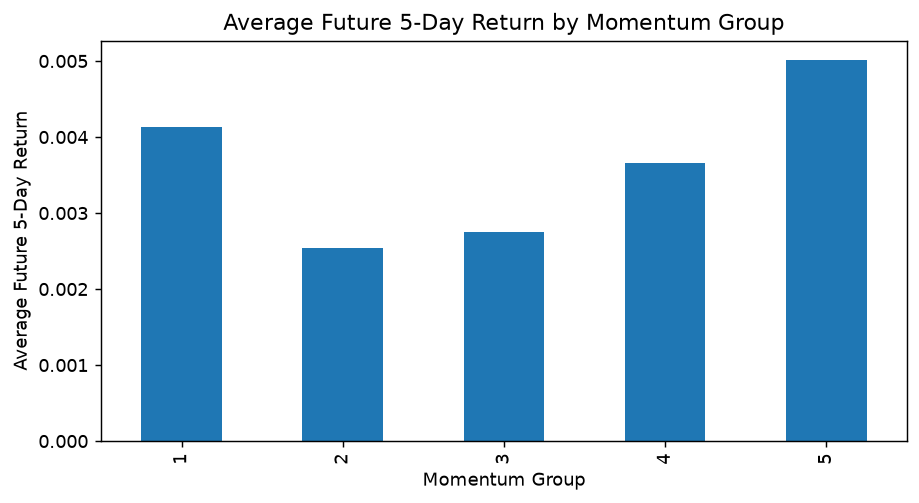

In [25]:
mean_group_return.plot(
    kind="bar",
    figsize=(8, 4),
    title="Average Future 5-Day Return by Momentum Group"
)

plt.xlabel("Momentum Group")
plt.ylabel("Average Future 5-Day Return")
plt.show()

In [26]:
group_return_wide = (
    group_return
    .pivot(
        index="date",
        columns="group",
        values="future_return_5"
    )
)

In [27]:
group_return_wide

Out[0]: 
group              1         2         3         4         5
date                                                        
2020-02-07  0.031981  0.041624  0.019243  0.030091  0.018146
2020-02-10  0.038146  0.049402  0.038611  0.055790  0.047097
2020-02-11  0.047512  0.038156  0.030815  0.040957  0.074280
2020-02-12  0.035124  0.027515  0.014531  0.031169  0.026943
2020-02-13  0.068185  0.042052  0.049921  0.049830  0.057335
...              ...       ...       ...       ...       ...
2025-12-18  0.027184  0.015682  0.007849  0.015676  0.036959
2025-12-19  0.015005  0.006394  0.013672  0.021135  0.046539
2025-12-22 -0.000291  0.002842  0.010473  0.007228  0.023079
2025-12-23  0.003193  0.001097  0.006112  0.017303  0.024157
2025-12-24 -0.000410 -0.003640  0.002759  0.001068  0.021356

[1430 rows x 5 columns]


In [28]:
group_return_wide["long_short"] = (
    group_return_wide[5]
    - group_return_wide[1]
)

In [29]:
print(
    "Mean Q5-Q1:",
    group_return_wide["long_short"].mean()
)

Mean Q5-Q1: 0.0008809367187677883


In [30]:
long_short_positive_ratio = (
    group_return_wide["long_short"] > 0
).mean()

print(
    "Q5-Q1 Positive Ratio:",
    long_short_positive_ratio
)

Q5-Q1 Positive Ratio: 0.5237762237762238


In [31]:
rebalance_dates = (
    panel_grouped["date"]
    .drop_duplicates()
    .sort_values()
    .iloc[::5]
)

In [32]:
backtest_data = panel_grouped[
    panel_grouped["date"].isin(rebalance_dates)
].copy()

In [33]:
bt_group_return = (
    backtest_data
    .groupby(["date", "group"])["future_return_5"]
    .mean()
    .reset_index()
)

In [34]:
bt_wide = (
    bt_group_return
    .pivot(
        index="date",
        columns="group",
        values="future_return_5"
    )
)

In [35]:
bt_wide["long_short"] = (
    bt_wide[5] - bt_wide[1]
)

In [36]:
bt_wide["nav_q5"] = (1 + bt_wide[5]).cumprod()

bt_wide["nav_q1"] = (1 + bt_wide[1]).cumprod()

bt_wide["nav_long_short"] = (
    1 + bt_wide["long_short"]
).cumprod()

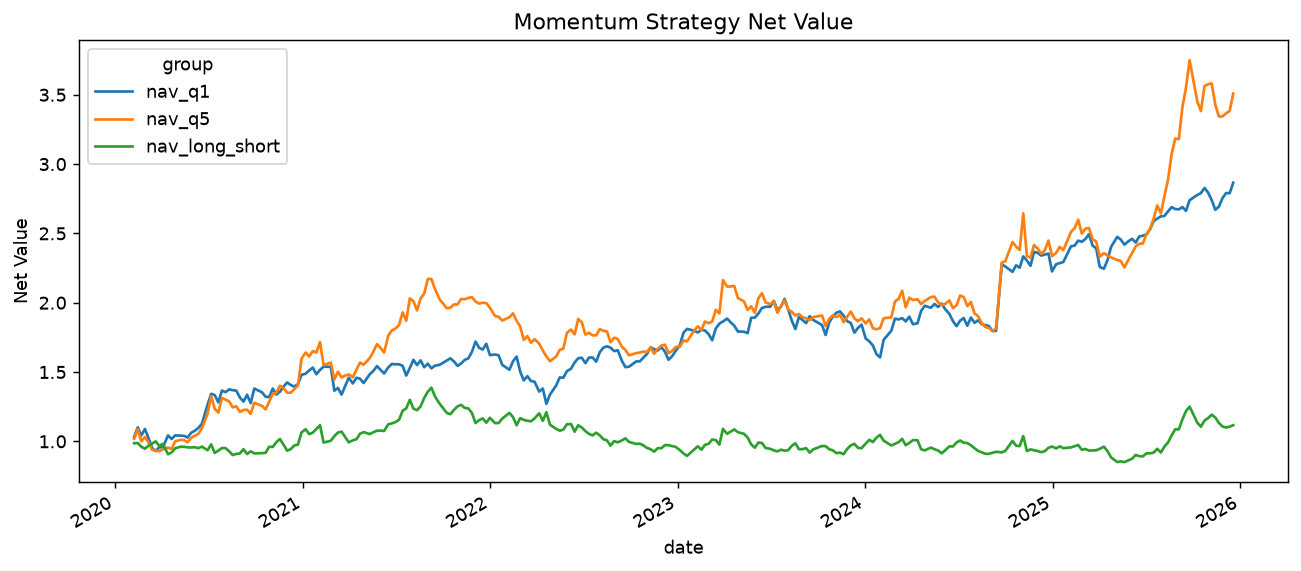

In [37]:
bt_wide[
    ["nav_q1", "nav_q5", "nav_long_short"]
].plot(
    figsize=(12, 5),
    title="Momentum Strategy Net Value"
)

plt.ylabel("Net Value")
plt.show()

In [38]:
periods_per_year = 252 / 5

In [39]:
annual_return = (
    (1 + bt_wide["long_short"].mean()) ** periods_per_year
    - 1
)

In [40]:
annual_vol = (
    bt_wide["long_short"].std()
    * np.sqrt(periods_per_year)
)

In [41]:
sharpe = (
    bt_wide["long_short"].mean()
    / bt_wide["long_short"].std()
    * np.sqrt(periods_per_year)
)

In [42]:
running_max = (
    bt_wide["nav_long_short"]
    .cummax()
)

In [43]:
drawdown = (
    bt_wide["nav_long_short"]
    / running_max
    - 1
)

In [44]:
max_drawdown = drawdown.min()

In [45]:
win_rate = (
    bt_wide["long_short"] > 0
).mean()

In [46]:
print("Annual Return:", annual_return)
print("Annual Volatility:", annual_vol)
print("Sharpe Ratio:", sharpe)
print("Max Drawdown:", max_drawdown)
print("Win Rate:", win_rate)

Annual Return: 0.042860515604586036
Annual Volatility: 0.21216908872435797
Sharpe Ratio: 0.19788420268941287
Max Drawdown: -0.38689174430275985
Win Rate: 0.513986013986014


In [47]:
bt_yearly = bt_wide.copy()

bt_yearly["year"] = bt_yearly.index.year

In [48]:
yearly_stats = (
    bt_yearly
    .groupby("year")["long_short"]
    .agg(["mean", "std", "count"])
)

In [49]:
periods_per_year = 252 / 5

yearly_stats["sharpe"] = (
    yearly_stats["mean"]
    / yearly_stats["std"]
    * np.sqrt(periods_per_year)
)

In [50]:
yearly_return = (
    bt_yearly
    .groupby("year")["long_short"]
    .apply(lambda x: (1 + x).prod() - 1)
)

In [51]:
yearly_stats["return"] = yearly_return

In [52]:
yearly_stats

Out[0]: 
          mean       std  count    sharpe    return
year                                               
2020  0.001827  0.030107     45  0.430882  0.064191
2021  0.002473  0.032877     49  0.534041  0.099171
2022 -0.003750  0.027259     48 -0.976535 -0.179571
2023  0.000235  0.029963     48  0.055761 -0.009287
2024  0.000706  0.030453     49  0.164686  0.012178
2025  0.003594  0.029337     47  0.869636  0.160328


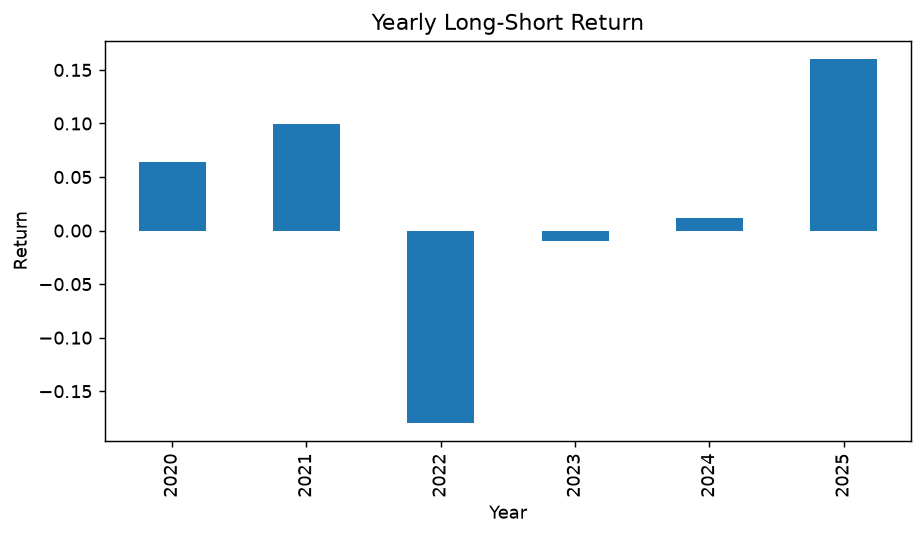

In [53]:
yearly_stats["return"].plot(
    kind="bar",
    figsize=(8, 4),
    title="Yearly Long-Short Return"
)

plt.xlabel("Year")
plt.ylabel("Return")
plt.show()

In [54]:
def evaluate_momentum_factor(panel, lookback, holding=5):
    df = panel.copy()

    # 1. 构造动量因子
    factor_col = f"momentum_{lookback}"

    df[factor_col] = (
        df.groupby("code")["close"]
        .pct_change(lookback)
    )

    # 2. 构造未来持有期收益
    df["future_return"] = (
        df.groupby("code")["close"]
        .shift(-holding)
        / df["close"]
        - 1
    )

    # 3. 删除无效样本
    df = df.dropna(
        subset=[factor_col, "future_return"]
    ).copy()

    # 4. 计算每日 RankIC
    daily_rank_ic = (
        df.groupby("date")
        .apply(
            lambda x: x[factor_col].corr(
                x["future_return"],
                method="spearman"
            )
        )
    )

    mean_rank_ic = daily_rank_ic.mean()
    rank_ic_std = daily_rank_ic.std()

    rank_icir = (
        mean_rank_ic / rank_ic_std
        if rank_ic_std != 0
        else np.nan
    )

    positive_ratio = (
        daily_rank_ic > 0
    ).mean()

    # 5. 每天分成五组
    df["group"] = (
        df.groupby("date")[factor_col]
        .transform(
            lambda x: pd.qcut(
                x.rank(method="first"),
                q=5,
                labels=[1, 2, 3, 4, 5]
            )
        )
    )

    # 6. 只取非重叠调仓日
    rebalance_dates = (
        df["date"]
        .drop_duplicates()
        .sort_values()
        .iloc[::holding]
    )

    bt_data = df[
        df["date"].isin(rebalance_dates)
    ].copy()

    # 7. 每个调仓日计算五组平均收益
    group_return = (
        bt_data
        .groupby(["date", "group"])["future_return"]
        .mean()
        .reset_index()
    )

    bt_wide = (
        group_return
        .pivot(
            index="date",
            columns="group",
            values="future_return"
        )
    )

    # 8. 多空收益
    bt_wide["long_short"] = (
        bt_wide[5] - bt_wide[1]
    )

    # 9. 多空净值
    bt_wide["nav_long_short"] = (
        1 + bt_wide["long_short"]
    ).cumprod()

    # 10. 绩效指标
    periods_per_year = 252 / holding

    sharpe = (
        bt_wide["long_short"].mean()
        / bt_wide["long_short"].std()
        * np.sqrt(periods_per_year)
    )

    running_max = (
        bt_wide["nav_long_short"].cummax()
    )

    drawdown = (
        bt_wide["nav_long_short"]
        / running_max
        - 1
    )

    max_drawdown = drawdown.min()

    mean_long_short = (
        bt_wide["long_short"].mean()
    )

    return {
        "lookback": lookback,
        "mean_rank_ic": mean_rank_ic,
        "rank_ic_std": rank_ic_std,
        "rank_icir": rank_icir,
        "positive_ratio": positive_ratio,
        "mean_q5_q1": mean_long_short,
        "sharpe": sharpe,
        "max_drawdown": max_drawdown
    }

In [55]:
lookbacks = [5, 10, 20, 60]

results = []

for lookback in lookbacks:
    result = evaluate_momentum_factor(
        panel,
        lookback=lookback,
        holding=5
    )

    results.append(result)


In [56]:
robustness_result = pd.DataFrame(results)

robustness_result

Out[0]: 
   lookback  mean_rank_ic  rank_ic_std  ...  mean_q5_q1    sharpe  max_drawdown
0         5     -0.007467     0.191369  ...    0.000776  0.204487     -0.309155
1        10     -0.009866     0.195175  ...    0.000817  0.215706     -0.296164
2        20     -0.015181     0.211297  ...    0.000833  0.197884     -0.386892
3        60     -0.018168     0.237431  ...    0.000603  0.117754     -0.532515

[4 rows x 8 columns]


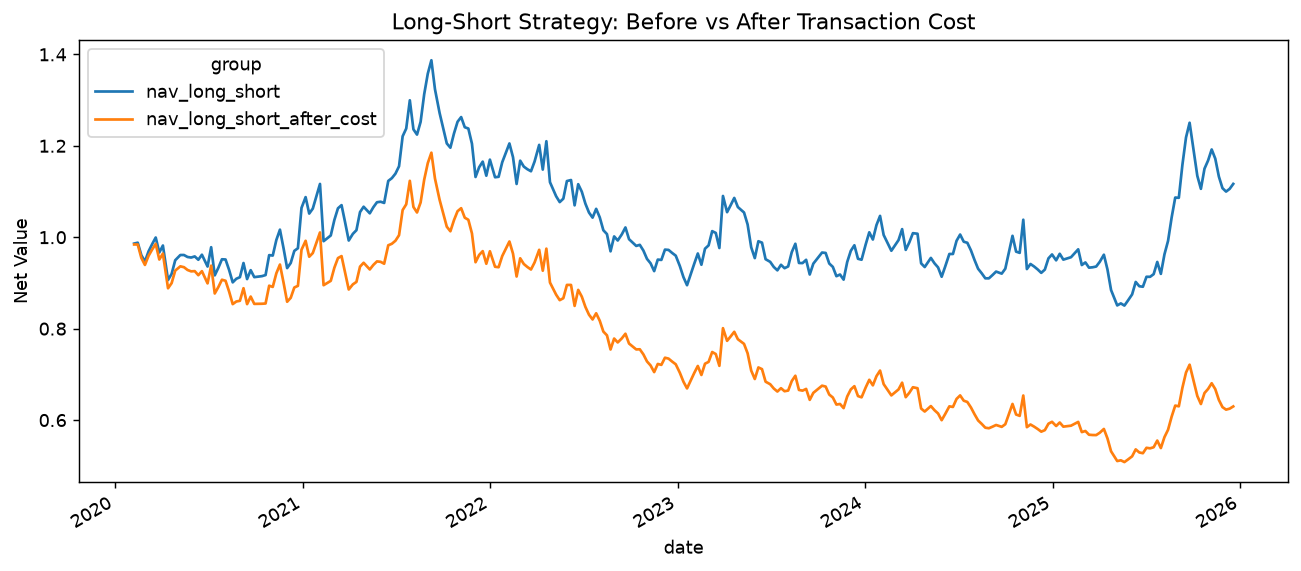

In [57]:
cost_per_side = 0.001

bt_wide["long_short_after_cost"] = (
    bt_wide["long_short"]
    - 2 * cost_per_side
)
bt_wide["nav_long_short_after_cost"] = (
    1 + bt_wide["long_short_after_cost"]
).cumprod()
bt_wide[
    ["nav_long_short", "nav_long_short_after_cost"]
].plot(
    figsize=(12, 5),
    title="Long-Short Strategy: Before vs After Transaction Cost"
)

plt.ylabel("Net Value")
plt.show()

In [58]:
periods_per_year = 252 / 5

after_cost_return = (
    bt_wide["long_short_after_cost"].mean()
    / bt_wide["long_short_after_cost"].std()
)
after_cost_sharpe = (
    bt_wide["long_short_after_cost"].mean()
    / bt_wide["long_short_after_cost"].std()
    * np.sqrt(periods_per_year)
)
after_cost_annual_return = (
    (1 + bt_wide["long_short_after_cost"].mean())
    ** periods_per_year
    - 1
)
after_cost_nav = bt_wide["nav_long_short_after_cost"]

after_cost_running_max = after_cost_nav.cummax()

after_cost_drawdown = (
    after_cost_nav
    / after_cost_running_max
    - 1
)

after_cost_max_drawdown = (
    after_cost_drawdown.min()
)
print(
    "Annual Return After Cost:",
    after_cost_annual_return
)

print(
    "Sharpe After Cost:",
    after_cost_sharpe
)

print(
    "Max Drawdown After Cost:",
    after_cost_max_drawdown
)

Annual Return After Cost: -0.05715127997560199
Sharpe After Cost: -0.27720856697863056
Max Drawdown After Cost: -0.5711707804228947


In [59]:
cost_bps_list = [5, 10, 20]

cost_results = []

In [60]:
for cost_bps in cost_bps_list:
    cost_per_side = cost_bps / 10000

    long_short_after_cost = (
        bt_wide["long_short"]
        - 2 * cost_per_side
    )

    periods_per_year = 252 / 5

    annual_return = (
        (1 + long_short_after_cost.mean())
        ** periods_per_year
        - 1
    )

    sharpe = (
        long_short_after_cost.mean()
        / long_short_after_cost.std()
        * np.sqrt(periods_per_year)
    )

    nav = (
        1 + long_short_after_cost
    ).cumprod()

    running_max = nav.cummax()

    drawdown = (
        nav / running_max - 1
    )

    max_drawdown = drawdown.min()

    cost_results.append({
        "cost_bps_per_side": cost_bps,
        "annual_return": annual_return,
        "sharpe": sharpe,
        "max_drawdown": max_drawdown
    })
cost_sensitivity = pd.DataFrame(cost_results)

cost_sensitivity

Out[0]: 
   cost_bps_per_side  annual_return    sharpe  max_drawdown
0                  5      -0.008380 -0.039662     -0.487198
1                 10      -0.057151 -0.277209     -0.571171
2                 20      -0.147744 -0.752301     -0.700278


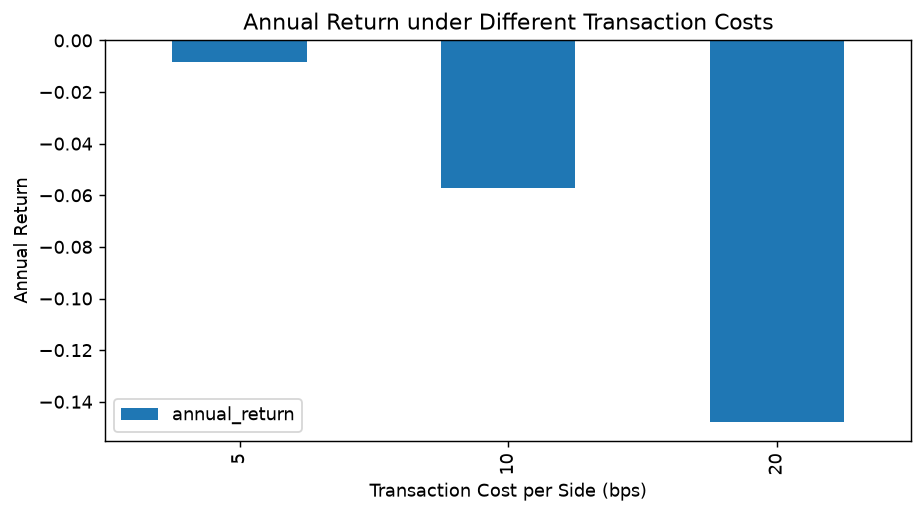

In [61]:
cost_sensitivity.plot(
    x="cost_bps_per_side",
    y="annual_return",
    kind="bar",
    figsize=(8, 4),
    title="Annual Return under Different Transaction Costs"
)

plt.xlabel("Transaction Cost per Side (bps)")
plt.ylabel("Annual Return")
plt.show()

In [62]:
# Export compact research artifacts for README and review.
output_dir = ROOT / "data/processed"
output_dir.mkdir(parents=True, exist_ok=True)
daily_rank_ic.rename("rank_ic").to_csv(output_dir / "daily_rank_ic.csv")
mean_group_return.to_csv(output_dir / "mean_group_returns.csv")
bt_wide.to_csv(output_dir / "backtest_20d.csv")
yearly_stats.to_csv(output_dir / "yearly_stats.csv")
robustness_result.to_csv(output_dir / "robustness.csv", index=False)
cost_sensitivity.to_csv(output_dir / "cost_sensitivity.csv", index=False)
